# Simplest PPO: 1D thrust correction

## Question
Can PPO learn, from scratch and in about a minute of training, to help a PID hold altitude when the drone suddenly
loses part of its thrust? How close does it get to an oracle that is told the exact loss?

## The task (deliberately minimal)
The drone moves **only up and down**. It hovers at 1.5 m for 10 s. At a random moment, total thrust drops by a random
amount. A crash is falling below 0.30 m.

| | |
|---|---|
| Physics | X2 numbers: 1.325 kg, total thrust command capped at 24 N, 0.125 s motor lag, 100 Hz. Hover needs 13.0 N, so **no controller can hover beyond a 45.8 % loss** (in 1D there is no spinning trick) |
| Fault | delivered thrust × (1 − loss), from the onset time on |
| **PID** | the 3D X2 PID's z gains (kp = kd = 1.75, ki = 1.0), integrator allowed to add up to 11 N, frozen while saturated |
| **PPO** | the same PID **plus a learned correction** of up to ±6 N, chosen 50 times a second |
| **Oracle** | the same PID, told the true loss the instant it happens: command / (1 − loss). A reference, not a real controller |
| **Stiff PID** | a second baseline with stiffer gains (kp 5, kd 3.5, ki 2), to check that PPO beats more than a deliberately gentle PID |

**What PPO sees (5 numbers):** height error, vertical velocity, the PID's command, its own previous correction, and
the accelerometer reading (delivered thrust / mass). It is **never** told the loss, the onset or that a fault exists.

**Reward per decision:** 1 − 2·|height error| − 0.1·(vertical speed)² − 0.01·(correction)², and −50 on a crash.

**Training:** each episode draws the onset uniformly from 2-5 s and the loss uniformly from 0-50 % (20 % of
episodes have no fault). Stable-Baselines3 PPO with two 2 × 32-unit networks (policy and value; 2,563 trained parameters, see section 2b), 8 parallel environments, 300,000
decisions per run (about 30 s), 3 training seeds.

**Test:** a fixed fault at 3.0 s at each of 0 / 12.5 / 25 / 37.5 / 50 %, plus a fine sweep from 0 to 50 % in 2.5 %
steps. Every controller flies every test.

In [1]:
import json, sys
from pathlib import Path
HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd() / "ppo_1d.ipynb")).resolve().parent
if not ((HERE / "sim1d.py").exists() and (HERE / "train.py").exists()):
    raise FileNotFoundError(f"sim1d.py and train.py not found in {HERE}: start Jupyter in this notebook's folder")
sys.path.insert(0, str(HERE))
import warnings; warnings.filterwarnings("ignore", message=".*Monitor.*")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sim1d, train as T
%matplotlib inline
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
DATA = T.DATA
COLOURS = {"pid": "tab:red", "stiff_pid": "tab:orange", "oracle": "tab:gray",
           "ppo_seed0": "tab:blue", "ppo_seed1": "tab:cyan", "ppo_seed2": "tab:purple"}
# print("experiment folder:", HERE)

## 1. Train and evaluate
Trains seeds 0-2 (300,000 decisions each) and then runs the test. **Resumable:**
- a checkpoint is saved every 50,000 decisions
- re-running continues from the newest one
- finished seeds (`model_final.zip`) are skipped

From a terminal: `python train.py` in this folder.

In [2]:
results = T.main(seeds=(0, 1, 2))
for s in (0, 1, 2):
    print(f"seed {s}:", json.loads((DATA / f"seed{s}" / "train_log.json").read_text()))

[seed 0] already trained, skipped


[seed 1] already trained, skipped
[seed 2] already trained, skipped


evaluation: 126 episodes -> data/eval
seed 0: [{'session': 0, 'finished': '2026-11-05T20:53:59', 'seconds': 28.6, 'steps_this_session': 300000, 'total_steps': 303104}]
seed 1: [{'session': 0, 'finished': '2026-11-05T20:54:38', 'seconds': 24.2, 'steps_this_session': 300000, 'total_steps': 303104}]
seed 2: [{'session': 0, 'finished': '2026-11-05T20:55:02', 'seconds': 23.3, 'steps_this_session': 300000, 'total_steps': 303104}]


## 2. Learning curves
Episode return during training (rolling mean over 50 episodes). A perfect 10 s hover scores about 500; a crash ends
the episode early with −50.

seed 0: 712 episodes; mean return first 100 = 185, last 100 = 390
seed 1: 711 episodes; mean return first 100 = 174, last 100 = 393
seed 2: 723 episodes; mean return first 100 = 170, last 100 = 381


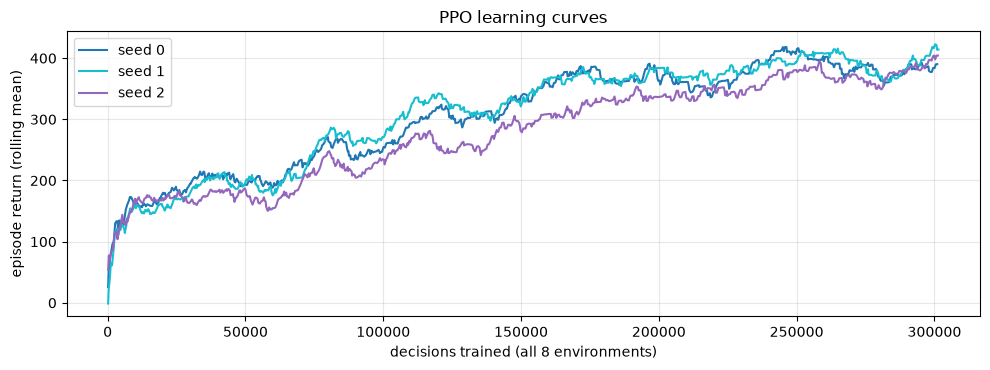

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for s in (0, 1, 2):
    lc = T.learning_curve(s)
    ax.plot(lc.steps, lc.r.rolling(50, min_periods=1).mean(), color=COLOURS[f"ppo_seed{s}"], label=f"seed {s}")
ax.set(xlabel="decisions trained (all 8 environments)", ylabel="episode return (rolling mean)", title="PPO learning curves")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
for s in (0, 1, 2):
    lc = T.learning_curve(s)
    print(f"seed {s}: {len(lc)} episodes; mean return first 100 = {lc.r[:100].mean():.0f}, last 100 = {lc.r[-100:].mean():.0f}")

## 2b. What PPO trains
PPO adjusts **2,563 numbers** in total, listed below from the saved seed-0 model:
- **Policy network (1,281 weights):** maps the 5 inputs to the average thrust correction. This is the part that
  flies. Layers: 5 → 32 → 32 → 1, with tanh activations.
- **Exploration spread (1 parameter, `log_std`):** during training the correction is sampled from a bell curve around
  the policy's output so PPO can try variations. Its width is learned too. In testing the noise is off and the
  average is used.
- **Value network (1,281 weights):** the same shape, but its output predicts how much reward is still to come. It is
  only used during training, to judge whether an action turned out better or worse than expected.

Everything else is a fixed setting, not trained: network size, learning rate, reward, PID gains and physics.

In [4]:
from stable_baselines3 import PPO
model = PPO.load(DATA / "seed0" / "model_final.zip", device="cpu")
rows = []
for name, p in model.policy.named_parameters():
    part = "value (training only)" if "value" in name else ("exploration spread" if name == "log_std" else "policy (flies)")
    rows.append({"parameter": name, "shape": tuple(p.shape), "count": p.numel(), "part": part})
params = pd.DataFrame(rows)
display(params)
print(params.groupby("part")["count"].sum().to_string())
print(f"total trained: {params['count'].sum()}")
print(f"learned exploration spread: std = {float(model.policy.log_std.detach().exp()):.2f} (x 6 N = ±{6 * float(model.policy.log_std.detach().exp()):.1f} N)")

,parameter,shape,count,part
0,log_std,"(1,)",1,exploration spread
1,mlp_extractor.policy_net.0.weight,"(32, 5)",160,policy (flies)
2,mlp_extractor.policy_net.0.bias,"(32,)",32,policy (flies)
3,mlp_extractor.policy_net.2.weight,"(32, 32)",1024,policy (flies)
4,mlp_extractor.policy_net.2.bias,"(32,)",32,policy (flies)
5,mlp_extractor.value_net.0.weight,"(32, 5)",160,value (training only)
6,mlp_extractor.value_net.0.bias,"(32,)",32,value (training only)
7,mlp_extractor.value_net.2.weight,"(32, 32)",1024,value (training only)
8,mlp_extractor.value_net.2.bias,"(32,)",32,value (training only)
9,action_net.weight,"(1, 32)",32,policy (flies)


part
exploration spread          1
policy (flies)           1281
value (training only)    1281
total trained: 2563
learned exploration spread: std = 0.90 (x 6 N = ±5.4 N)


## 3. Test results

In [5]:
res = pd.read_csv(DATA / "eval" / "summary.csv")
grid = res[res.in_test_grid].copy()
grid["loss"] = (grid.loss * 100).map("{:.1f}%".format)
order = ["pid", "stiff_pid", "ppo_seed0", "ppo_seed1", "ppo_seed2", "oracle"]
for col, label in [("crashed", "crashed?"), ("max_drop", "largest drop below 1.5 m [m]"), ("min_z", "lowest height [m]"),
                   ("recovery_time", "recovery time [s] (back within 5 cm for 0.5 s; 0 = never left)"),
                   ("final_err", "height error at the end [m]")]:
    print(label)
    display(grid.pivot(index="loss", columns="controller", values=col)[order].round(3))

crashed?


controller,pid,stiff_pid,ppo_seed0,ppo_seed1,ppo_seed2,oracle
loss,,,,,,
0.0%,False,False,False,False,False,False
12.5%,False,False,False,False,False,False
25.0%,True,False,False,False,False,False
37.5%,True,True,False,False,False,False
50.0%,True,True,True,True,True,True


largest drop below 1.5 m [m]


controller,pid,stiff_pid,ppo_seed0,ppo_seed1,ppo_seed2,oracle
loss,,,,,,
0.0%,0.000,0.000,0.000,0.000,0.000,0.000
12.5%,0.711,0.265,0.000,0.005,0.000,0.058
25.0%,1.500,0.636,0.029,0.039,0.019,0.117
37.5%,1.500,1.210,0.840,0.822,0.857,0.175
50.0%,1.500,1.500,1.500,1.500,1.500,1.500


lowest height [m]


controller,pid,stiff_pid,ppo_seed0,ppo_seed1,ppo_seed2,oracle
loss,,,,,,
0.0%,1.500,1.500,1.500,1.500,1.500,1.500
12.5%,0.789,1.235,1.500,1.495,1.500,1.442
25.0%,0.000,0.864,1.471,1.461,1.481,1.383
37.5%,0.000,0.290,0.660,0.678,0.643,1.325
50.0%,0.000,0.000,0.000,0.000,0.000,0.000


recovery time [s] (back within 5 cm for 0.5 s; 0 = never left)


controller,pid,stiff_pid,ppo_seed0,ppo_seed1,ppo_seed2,oracle
loss,,,,,,
0.0%,NaN,NaN,NaN,NaN,NaN,NaN
12.5%,NaN,4.27,0.00,0.00,0.00,1.25
25.0%,NaN,5.65,0.00,0.00,0.00,1.69
37.5%,NaN,NaN,3.94,3.93,4.59,1.82
50.0%,NaN,NaN,NaN,NaN,NaN,NaN


height error at the end [m]


controller,pid,stiff_pid,ppo_seed0,ppo_seed1,ppo_seed2,oracle
loss,,,,,,
0.0%,0.000,0.000,0.021,0.012,0.030,0.00
12.5%,0.037,0.009,0.005,0.004,0.019,0.01
25.0%,0.135,0.022,0.017,0.025,0.004,0.02
37.5%,0.450,0.050,0.018,0.010,0.036,0.03
50.0%,1.500,1.500,1.500,1.500,1.500,1.50


### Height over time
Every controller at 25 % and 37.5 % loss (fault at 3 s, dashed line).

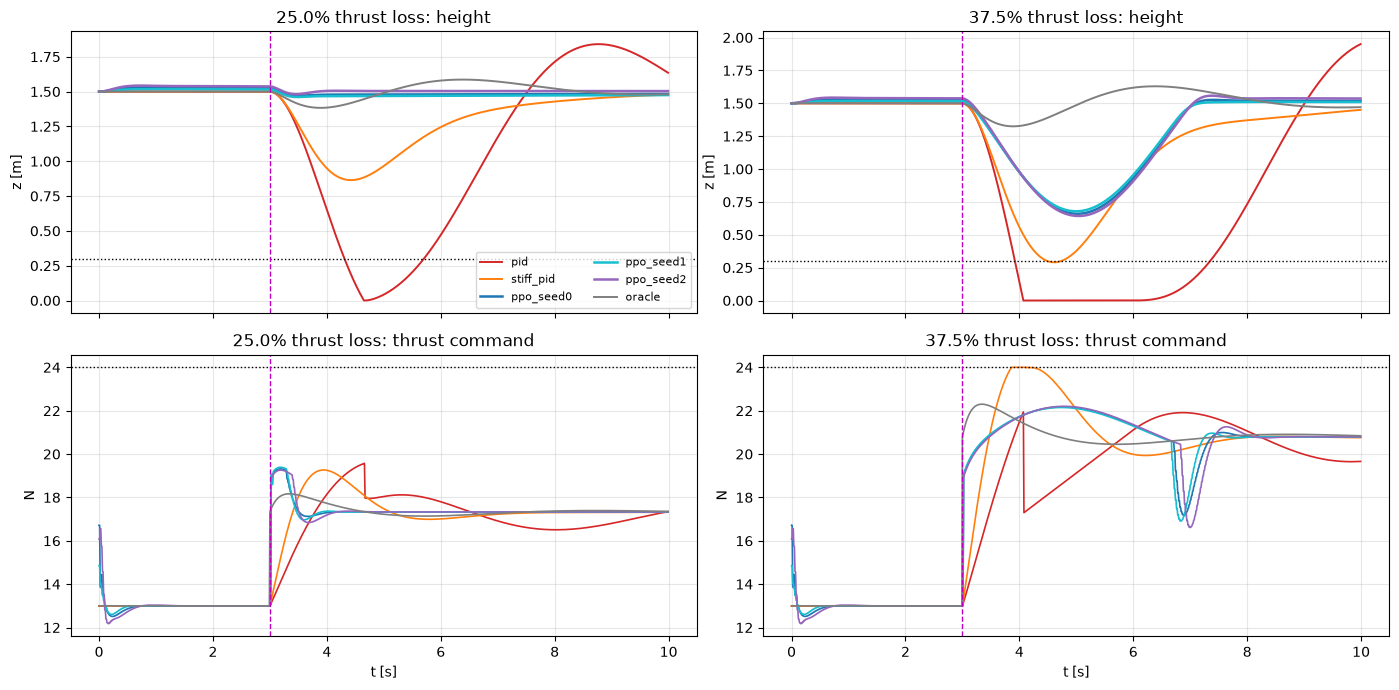

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for col, tag in enumerate(["25.0", "37.5"]):
    for name in order:
        lg = pd.read_csv(DATA / "eval" / f"{name}_loss{tag}.csv")
        axes[0, col].plot(lg.t, lg.z, color=COLOURS[name], lw=1.8 if name.startswith("ppo") else 1.4, label=name)
        axes[1, col].plot(lg.t, lg.command, color=COLOURS[name], lw=1.2, label=name)
    axes[0, col].axhline(sim1d.CRASH_Z, color="k", ls=":", lw=1)
    axes[0, col].set(title=f"{tag}% thrust loss: height", ylabel="z [m]")
    axes[1, col].axhline(sim1d.MAX_THRUST, color="k", ls=":", lw=1)
    axes[1, col].set(title=f"{tag}% thrust loss: thrust command", ylabel="N", xlabel="t [s]")
    for a in axes[:, col]:
        a.axvline(3.0, color="m", ls="--", lw=1); a.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8, ncol=2)
plt.tight_layout()

### What the policy learned
The PPO correction (seed 0) at each loss level. It stays near zero in a healthy hover (about +0.1-0.2 N), then jumps to
its +6 N maximum within one decision of the fault: the accelerometer shows the thrust is suddenly missing.

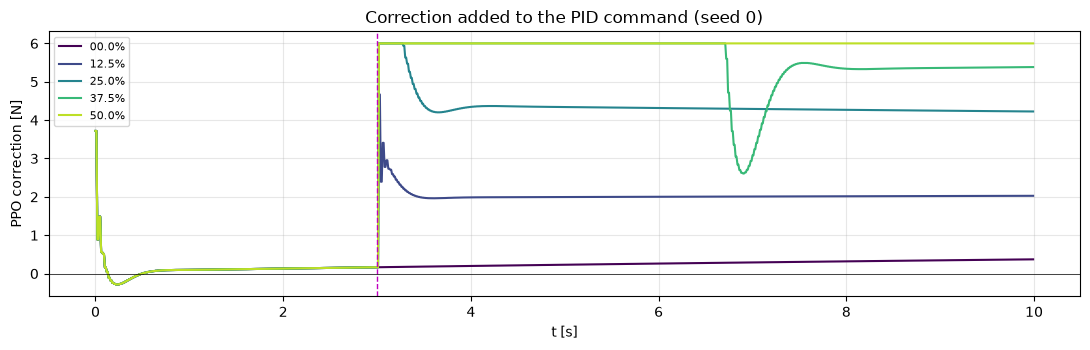

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for tag, c in zip(["00.0", "12.5", "25.0", "37.5", "50.0"], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    lg = pd.read_csv(DATA / "eval" / f"ppo_seed0_loss{tag}.csv")
    ax.plot(lg.t, lg.correction, color=c, label=f"{tag}%")
ax.axvline(3.0, color="m", ls="--", lw=1); ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="t [s]", ylabel="PPO correction [N]", title="Correction added to the PID command (seed 0)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()

### The whole range: 0-50 % in 2.5 % steps

largest loss survived in the sweep:
controller
pid          17.5 %
stiff_pid    35.0 %
ppo_seed0    40.0 %
ppo_seed1    40.0 %
ppo_seed2    40.0 %
oracle       45.0 %
Name: loss, dtype: str


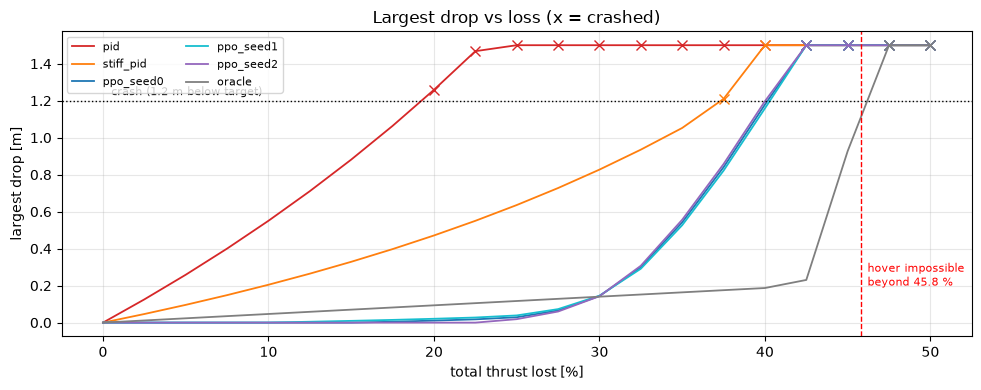

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in order:
    s = res[res.controller == name].sort_values("loss")
    ok, bad = s[~s.crashed], s[s.crashed]
    ax.plot(s.loss * 100, s.max_drop, "-", color=COLOURS[name], lw=1.3, label=name)
    ax.plot(bad.loss * 100, bad.max_drop, "x", color=COLOURS[name], ms=7)
ax.axvline(45.8, color="r", ls="--", lw=1); ax.text(46.2, 0.2, "hover impossible\nbeyond 45.8 %", fontsize=8, color="r")
ax.axhline(1.5 - sim1d.CRASH_Z, color="k", ls=":", lw=1); ax.text(0.5, 1.23, "crash (1.2 m below target)", fontsize=8)
ax.set(xlabel="total thrust lost [%]", ylabel="largest drop [m]", title="Largest drop vs loss (x = crashed)")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout()
surv = res[~res.crashed].groupby("controller").loss.max().reindex(order)
print("largest loss survived in the sweep:"); print((surv * 100).round(1).astype(str) + " %")

## 4. Is it consistent across training seeds?

In [9]:
p = res[res.controller.str.startswith("ppo") & res.in_test_grid & (res.loss < 0.45)]
p.pivot(index="loss", columns="controller", values="max_drop").assign(
    spread=lambda d: d.max(axis=1) - d.min(axis=1)).round(3)

controller,ppo_seed0,ppo_seed1,ppo_seed2,spread
loss,,,,
0.000,0.000,0.000,0.000,0.000
0.125,0.000,0.005,0.000,0.005
0.250,0.029,0.039,0.019,0.020
0.375,0.840,0.822,0.857,0.036


## 5. The first reward attempt (squared height penalty)
Same everything, but reward 1 − e² − 0.1·vz² − 0.01·a². In a healthy hover it flew well above the 1.5 m target.

In [10]:
ATTEMPT1 = DATA / "attempt1_squared_reward"
if not ATTEMPT1.exists():
    print("First-attempt data (squared reward) is not included; the current code cannot regenerate it. Skipping.")
else:
    att = pd.read_csv(ATTEMPT1 / "eval" / "summary.csv")
    a = att[att.in_test_grid & (att.controller == "ppo_seed0")].set_index("loss")
    b = res[res.in_test_grid & (res.controller == "ppo_seed0")].set_index("loss")
    lg1 = pd.read_csv(ATTEMPT1 / "eval" / "ppo_seed0_loss00.0.csv")
    lg2 = pd.read_csv(DATA / "eval" / "ppo_seed0_loss00.0.csv")
    print(f"healthy hover, highest point: squared reward {lg1.z.max():.3f} m, linear reward {lg2.z.max():.3f} m (target 1.5 m)")
    display(pd.DataFrame({"drop, squared": a.max_drop, "drop, linear": b.max_drop,
                          "end error, squared": a.final_err, "end error, linear": b.final_err}).round(3))

healthy hover, highest point: squared reward 1.774 m, linear reward 1.530 m (target 1.5 m)


,"drop, squared","drop, linear","end error, squared","end error, linear"
loss,,,,
0.000,0.000,0.000,0.152,0.021
0.125,0.000,0.000,0.084,0.005
0.250,0.005,0.029,0.005,0.017
0.375,1.192,0.840,0.068,0.018
0.500,1.500,1.500,1.500,1.500


## 6. Results
**PPO learned a useful correction in about 30 seconds of training, consistently across 3 seeds.** The mean episode
return rose from about 170-185 (first 100 episodes) to 381-393 (last 100).

| Total loss | Gentle PID | Stiff PID | **PID + PPO** (3 seeds) | Oracle |
|---|---|---|---|---|
| 0 % | holds 1.5 m | holds 1.5 m | holds, 1.7-4.3 cm high | holds 1.5 m |
| 12.5 % | drops 0.71 m | drops 0.27 m | **drops ≤ 0.005 m** | drops 0.06 m |
| 25 % | **crashes** | drops 0.64 m | **drops 0.02-0.04 m** | drops 0.12 m |
| 37.5 % | **crashes** | **crashes** | **survives**, drops 0.82-0.86 m | drops 0.18 m |
| 50 % | crashes | crashes | crashes | crashes (physically impossible) |

- **It reacts faster than any PID.** Within one decision (0.02 s) of the fault, the accelerometer shows that thrust
  is missing and the policy jumps to its full +6 N correction. The PID only reacts once the height error has grown. At 12.5 % and 25 % this keeps the drone within 4 cm of the target, **even better than the oracle**. The
  oracle knows the loss perfectly but scales the same gentle PID, while PPO learned a more aggressive response.
- **It extends survival to 37.5 %**, where both PIDs crash. In the fine sweep it survives up to 40 %, against 17.5 %
  (gentle PID), 35 % (stiff PID) and 45 % (oracle).
- **It is still far from the oracle at 37.5 %** (0.84 m drop against 0.18 m), and part of that is my design: a
  37.5 % loss needs about +7.8 N of extra command (20.8 N against 13 N), more than the ±6 N correction range I gave
  PPO. The policy holds +6 N and the PID's integrator has to supply the rest slowly. A wider correction range would
  probably close much of the gap.
- **Consistent:** the three seeds differ by at most 0.04 m in drop at any loss level.
- **50 % is lost by every controller**, as physics requires (12 N available, 13 N needed).
- **A small cost in the healthy case:** with no fault, the policy hovers 1.7-4.3 cm above the target. That is a mild
  version of the hedging the first reward produced (0.27 m too high) and fixed.

## Conclusion
Even the simplest PPO, with 5 inputs, 1 output, a policy network of 1,281 weights (2,563 parameters trained in all,
including the value network that is only used during training) and 30 s of training, learns the key skill:
**notice a sudden thrust loss from the accelerometer and compensate immediately**, instead of waiting for altitude
error to build up. In this 1D setting that cuts the drop at 25 % loss from 0.64 m (stiff PID) or a crash (gentle PID)
to 3 cm, and survives 37.5 %.

**What this does and doesn't show**
- **It shows the training setup works:** environment, reward, PPO and evaluation, with the pitfalls found (integrator
  limit, reward hedging). It also shows that the accelerometer contains the information needed to react to a fault.
- **It doesn't carry over directly to the 3D X2.** A total-thrust loss in 1D is a different problem from one weak
  motor in 3D, which also tilts and spins the drone. The numbers can't be compared with 3D results.
- **Small evaluation:** one fixed onset time, one flight per loss level per controller, and no sensor noise. The
  healthy-hover offset shows the reward still trades a little accuracy for safety.
- **Natural next steps:** widen the correction range, add sensor noise, test held-out onset times, then the 3D
  residual version on the X2 with single-motor faults.

## Run record

In [11]:
m = json.loads((DATA / "manifest.json").read_text())
print("versions:", m["versions"]); print("PPO settings:", m["ppo"]); print("runs finished:", [r["finished"] for r in m["runs"]])

versions: {'numpy': '2.5.4', 'torch': '2.15.0', 'gymnasium': '1.4.0', 'stable_baselines3': '2.9.2'}
PPO settings: {'n_steps': 1024, 'batch_size': 256, 'n_epochs': 10, 'learning_rate': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.2, 'ent_coef': 0.0, 'policy_kwargs': {'net_arch': [32, 32]}}
runs finished: ['2026-11-05T20:54:01', '2026-11-05T20:55:05', '2026-11-05T20:58:21', '2026-11-05T20:59:17', '2026-11-05T20:59:47', '2026-11-05T21:27:01', '2026-11-05T23:35:55']
